# chuẩn bị dữ liệu

In [ ]:
import os
import pandas as pd
import numpy as np
from pathlib import Path

def load_data(path: str, nrows: int = None) -> pd.DataFrame:
    transaction_path = os.path.join(path, "train_transaction.csv")
    identity_path = os.path.join(path, "train_identity.csv")
    tr = pd.read_csv(transaction_path, nrows=nrows)
    idt = pd.read_csv(identity_path, nrows=nrows)
    # merge 2 dataframes theo TransactionID
    df = tr.merge(idt, on="TransactionID", how="left")
    print(f"[load_data] merged: {df.shape}")
    return df

# lấy path của root directory
ROOT = Path.cwd().parent
print("Project root:", ROOT)

# lấy path của raw data directory
DATA_PATH = ROOT / "data" / "raw"
print("Data path:", DATA_PATH)

df = load_data(path=str(DATA_PATH), nrows=None)

# kiểm tra số lượng ô thiếu ban đầu
total_missing_original = df.isna().sum().sum()
total_cells_original = df.shape[0] * df.shape[1]
print(f"Số ô thiếu ban đầu: {total_missing_original:,} / {total_cells_original:,} "
      f"({total_missing_original/total_cells_original:.1%})")

Project root: d:\University\semester7\Machine Learning\assignment\fraud-detection
Data path: d:\University\semester7\Machine Learning\assignment\fraud-detection\data\raw
[load_data] merged: (590540, 434)
Số ô thiếu ban đầu: 115,523,073 / 256,294,360 (45.1%)


In [2]:
print("Số dòng, số cột:", df.shape)
df.head()

Số dòng, số cột: (590540, 434)


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [9]:
# kiểu data ở từng cột
dtype_summary = df.dtypes.value_counts()
print(dtype_summary)

float64    399
str         31
int64        4
Name: count, dtype: int64


In [10]:
# thống kê số lượng và tỷ lệ phần trăm các giao dịch gian lận
fraud_count = df["isFraud"].value_counts()
fraud_pct = df["isFraud"].value_counts(normalize=True) * 100
print("Số lượng:\n", fraud_count)
print("\nTỷ lệ phần trăm:\n", fraud_pct)

Số lượng:
 isFraud
0    569877
1     20663
Name: count, dtype: int64

Tỷ lệ phần trăm:
 isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64


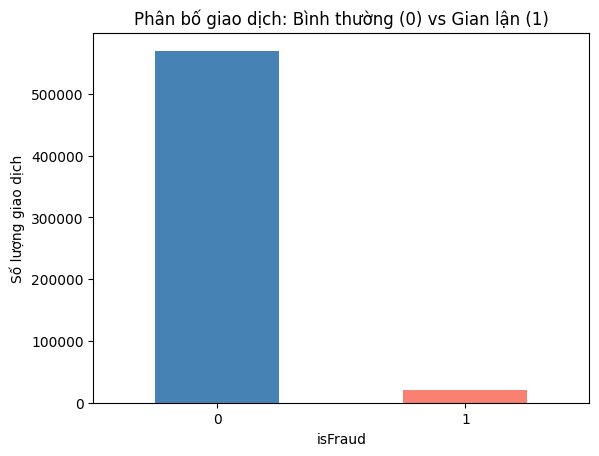

In [12]:
# biểu đồ cột so sánh số lượng giao dịch bình thường và gian lận
import matplotlib.pyplot as plt

fraud_count.plot(kind="bar", color=["steelblue", "salmon"])
plt.title("Phân bố giao dịch: Bình thường (0) vs Gian lận (1)")
plt.xlabel("isFraud")
plt.ylabel("Số lượng giao dịch")
plt.xticks(rotation=0)
plt.savefig(ROOT / "reports" / "figures" / "fraud_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# thống kê tỉ lệ phần trăm các giá trị bị thiếu trong từng cột
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print(missing_pct.head(20))

id_24    99.196159
id_25    99.130965
id_07    99.127070
id_08    99.127070
id_21    99.126393
id_26    99.125715
id_27    99.124699
id_23    99.124699
id_22    99.124699
dist2    93.628374
D7       93.409930
id_18    92.360721
D13      89.509263
D14      89.469469
D12      89.041047
id_04    88.768923
id_03    88.768923
D6       87.606767
id_33    87.589494
id_09    87.312290
dtype: float64


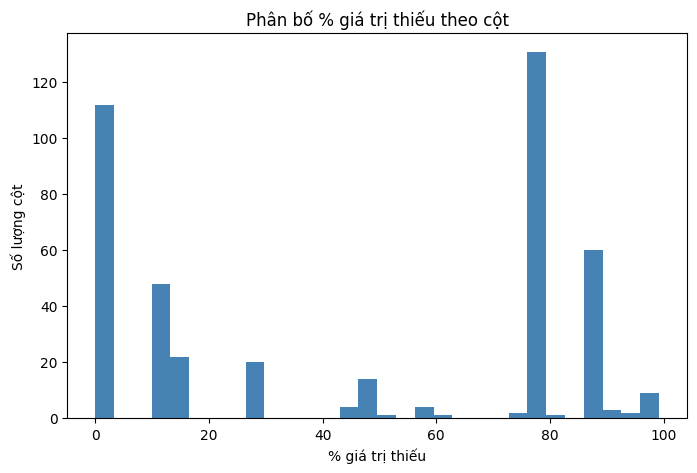

In [14]:
plt.figure(figsize=(8, 5))
missing_pct.plot(kind="hist", bins=30, color="steelblue")
plt.title("Phân bố % giá trị thiếu theo cột")
plt.xlabel("% giá trị thiếu")
plt.ylabel("Số lượng cột")
plt.savefig(ROOT / "reports" / "figures" / "missing_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Mục 1: Mô tả bài toán

**Lĩnh vực:** Phát hiện gian lận tài chính (Financial Fraud Detection) trong
giao dịch thương mại điện tử.

**Nguồn dữ liệu:** Bộ dữ liệu IEEE-CIS Fraud Detection, do công ty Vesta
Corporation cung cấp thông qua cuộc thi Kaggle (2019). Sau khi merge 2 file
`train_transaction.csv` và `train_identity.csv` theo `TransactionID`, tập
dữ liệu gồm **590,540 giao dịch** với **434 đặc trưng** (399 cột số, 31 cột
phân loại, 4 cột số nguyên).

**Vấn đề:** Dữ liệu mất cân bằng lớp (class imbalance) rất nghiêm trọng —
chỉ **20,663 giao dịch (3.50%)** là gian lận, còn lại **569,877 giao dịch
(96.50%)** là bình thường. Đây là thách thức cốt lõi: một mô hình đoán bừa
"không gian lận" cho mọi giao dịch vẫn đạt 96.5% accuracy, nên Accuracy
không phải là thước đo phù hợp cho bài toán này — cần dùng Precision,
Recall, F1-score và PR-AUC.

Ngoài ra, dữ liệu có mức độ thiếu giá trị (missing value) không đồng đều:
một nhóm lớn khoảng 130 cột (chủ yếu các đặc trưng ẩn danh `V1`-`V339`)
thiếu khoảng 75-80%, và một nhóm khác (`id_*`, `D*`, `dist2`) thiếu tới
85-99%. Việc xử lý hợp lý nhóm dữ liệu thiếu này là trọng tâm của bước
tiền xử lý.

## Bước 1-2: Phân tích mức độ thiếu dữ liệu và kiểm định ý nghĩa thống kê

Thay vì chọn đại 1 ngưỡng % thiếu rồi bỏ cột, ta làm theo quy trình có căn
cứ số liệu:

1. Chia cột thành 3 nhóm theo % thiếu: an toàn (<25%), nghi ngờ (25-75%),
   ứng viên bỏ (>=75%).
2. Với 2 nhóm sau, kiểm tra xem việc **thiếu/không thiếu** ở cột đó có
   thực sự liên quan đến việc giao dịch có gian lận hay không, bằng
   **kiểm định Chi-square** kết hợp **Cramér's V** (đo độ mạnh liên hệ,
   không bị "ảo" bởi cỡ mẫu lớn như p-value đơn thuần).
3. Cột có Cramér's V >= 0.10 được coi là có tín hiệu thật (dù yếu), cột
   dưới ngưỡng này được coi là nhiễu và bị loại.

**Lưu ý:** bước này chỉ dùng để *chọn ra danh sách cột* cần giữ — bản
thân việc phân tích không "học tham số" để áp dụng lại cho dữ liệu mới,
nên không gây rò rỉ dữ liệu giống như bước impute/encode.

In [15]:
# sắp xếp các cột theo tỷ lệ phần trăm giá trị thiếu
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)

safe_cols = missing_pct[missing_pct < 25].index.tolist()
suspect_cols = missing_pct[(missing_pct >= 25) & (missing_pct < 75)].index.tolist()
drop_candidate_cols = missing_pct[missing_pct >= 75].index.tolist()

print(f"An toàn (<25%):      {len(safe_cols)} cột")
print(f"Nghi ngờ (25-75%):   {len(suspect_cols)} cột")
print(f"Ứng viên bỏ (>=75%): {len(drop_candidate_cols)} cột")

An toàn (<25%):      182 cột
Nghi ngờ (25-75%):   44 cột
Ứng viên bỏ (>=75%): 208 cột


In [16]:
from scipy.stats import chi2_contingency

# hàm tính Cramér's V và p-value từ bảng tần số chéo
def cramers_v(contingency_table):
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1
    return np.sqrt(chi2 / (n * min_dim)), p

cols_to_check = suspect_cols + drop_candidate_cols
alpha_corrected = 0.05 / len(cols_to_check)   # Bonferroni correction

signal_results = []
for col in cols_to_check:
    is_missing = df[col].isna()
    contingency_table = pd.crosstab(is_missing, df["isFraud"])
    v, p_value = cramers_v(contingency_table)
    signal_results.append({
        "column": col,
        "missing_pct": missing_pct[col],
        "p_value": p_value,
        "cramers_v": v,
        "meaningful_effect": v >= 0.10,
    })

signal_df = pd.DataFrame(signal_results).sort_values("cramers_v", ascending=False)
print(signal_df["meaningful_effect"].value_counts())
signal_df.head(20)

meaningful_effect
True     146
False    106
Name: count, dtype: int64


,column,missing_pct,p_value,cramers_v,meaningful_effect
54,D7,93.409930,0.0,0.164459,True
58,D12,89.041047,0.0,0.157329,True
57,D14,89.469469,0.0,0.151212,True
61,D6,87.606767,0.0,0.144219,True
64,D8,87.312290,0.0,0.144109,True
65,id_10,87.312290,0.0,0.144109,True
63,id_09,87.312290,0.0,0.144109,True
66,D9,87.312290,0.0,0.144109,True
56,D13,89.509263,0.0,0.140404,True
169,R_emaildomain,76.751617,0.0,0.140117,True


## Bước 3: Áp dụng luật quyết định — bỏ cột nhiễu, giữ tín hiệu dưới dạng cờ

- Cột thiếu <25%: giữ nguyên, sẽ impute bình thường ở bước sau.
- Cột thiếu >=25% **và** Cramér's V >= 0.10: giữ lại cột gốc để impute,
  **đồng thời** tạo thêm 1 cột cờ `_is_missing` (0/1) — vì bản thân việc
  "có/không có giá trị" ở các cột này đã được chứng minh là mang tín
  hiệu, tách riêng ra giúp model khai thác rõ ràng hơn.
- Cột thiếu >=25% **và** Cramér's V < 0.10: bỏ hẳn, vì đã chứng minh việc
  thiếu/không thiếu ở các cột này không liên quan đến gian lận.

In [17]:
meaningful_cols = signal_df.loc[signal_df["meaningful_effect"], "column"].tolist()
noise_cols = signal_df.loc[~signal_df["meaningful_effect"], "column"].tolist()

for col in meaningful_cols:
    df[f"{col}_is_missing"] = df[col].isna().astype(int)

df_clean = df.drop(columns=noise_cols)

print(f"Giữ bình thường: {len(safe_cols)} cột")
print(f"Giữ + thêm cờ:   {len(meaningful_cols)} cột")
print(f"Bỏ hẳn:          {len(noise_cols)} cột")
print(f"Shape sau Bước 3: {df_clean.shape}")

C:\Users\pc\AppData\Local\Temp\ipykernel_15492\4074192466.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{col}_is_missing"] = df[col].isna().astype(int)
C:\Users\pc\AppData\Local\Temp\ipykernel_15492\4074192466.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{col}_is_missing"] = df[col].isna().astype(int)
C:\Users\pc\AppData\Local\Temp\ipykernel_15492\4074192466.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance

Giữ bình thường: 182 cột
Giữ + thêm cờ:   146 cột
Bỏ hẳn:          106 cột
Shape sau Bước 3: (590540, 474)


C:\Users\pc\AppData\Local\Temp\ipykernel_15492\4074192466.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{col}_is_missing"] = df[col].isna().astype(int)


## Bước 4: Chia tập Train / Validation / Test THEO THỜI GIAN

Đây là bước quan trọng nhất để tránh rò rỉ dữ liệu. Vì giao dịch có trình
tự thời gian thực tế, ta sắp xếp theo `TransactionDT` rồi cắt: 70% đầu
(cũ nhất) làm train, 15% giữa làm validation, 15% cuối (mới nhất) làm
test — mô phỏng đúng tình huống thực tế: mô hình chỉ được huấn luyện từ
quá khứ, kiểm tra trên "tương lai" nó chưa từng thấy.

**Mọi bước xử lý tiếp theo (impute, encode, tính tần suất) chỉ được học
tham số từ `train_df`, sau đó áp dụng lại cho `val_df` và `test_df`.**

In [18]:
def time_based_split(df, train_frac=0.70, val_frac=0.15):
    df_sorted = df.sort_values("TransactionDT").reset_index(drop=True)
    n = len(df_sorted)
    train_end = int(n * train_frac)
    val_end = int(n * (train_frac + val_frac))
    train_df = df_sorted.iloc[:train_end].copy()
    val_df = df_sorted.iloc[train_end:val_end].copy()
    test_df = df_sorted.iloc[val_end:].copy()
    print(f"train: {train_df.shape}, val: {val_df.shape}, test: {test_df.shape}")
    return train_df, val_df, test_df

train_df, val_df, test_df = time_based_split(df_clean)

train: (413378, 474), val: (88581, 474), test: (88581, 474)


## Bước 5: Impute giá trị thiếu — CHỈ HỌC THAM SỐ TỪ TRAIN

Tính median (cột số) và giá trị thay thế (cột chữ) **chỉ trên `train_df`**,
rồi dùng đúng những giá trị đó để điền vào cả train, val và test. Điều
này đảm bảo val/test không "nhìn thấy" thông tin thống kê của chính nó
hay của test — giống hệt tình huống thực tế khi mô hình gặp dữ liệu mới
hoàn toàn.

In [19]:
numeric_cols = df_clean.select_dtypes(include=["float64", "int64"]).columns.tolist()
categorical_cols = df_clean.select_dtypes(include=["object"]).columns.tolist()
numeric_cols.remove("isFraud")

# học giá trị impute chỉ từ train
impute_values = {}
for col in numeric_cols:
    impute_values[col] = train_df[col].median()
for col in categorical_cols:
    impute_values[col] = "missing"

# áp dụng cùng bộ giá trị này cho cả 3 tập
for split_df in [train_df, val_df, test_df]:
    for col in numeric_cols:
        split_df[col] = split_df[col].fillna(impute_values[col])
    for col in categorical_cols:
        split_df[col] = split_df[col].fillna(impute_values[col])

print("Train missing:", train_df.isna().sum().sum())
print("Val missing:", val_df.isna().sum().sum())
print("Test missing:", test_df.isna().sum().sum())

C:\Users\pc\AppData\Local\Temp\ipykernel_15492\1744994419.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(include=["object"]).columns.tolist()


Train missing: 0
Val missing: 0
Test missing: 0


## Bước 6: Mã hóa cột phân loại (Label Encoding) — CHỈ FIT TRÊN TRAIN

`LabelEncoder` "học" (fit) danh sách các giá trị duy nhất chỉ từ
`train_df`. Khi áp dụng cho `val_df`/`test_df`, có thể gặp giá trị lạ mà
train chưa từng thấy (ví dụ 1 hãng điện thoại mới) — các giá trị này được
gán thành `"unknown"` thay vì gây lỗi.

In [20]:
from sklearn.preprocessing import LabelEncoder

encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    train_df[col] = train_df[col].astype(str)
    le.fit(train_df[col])
    encoders[col] = le

for split_df in [train_df, val_df, test_df]:
    for col in categorical_cols:
        split_df[col] = split_df[col].astype(str)
        # giá trị lạ (chưa từng thấy ở train) gán "unknown"
        split_df[col] = split_df[col].where(split_df[col].isin(encoders[col].classes_), "unknown")

# thêm "unknown" vào danh sách lớp của từng encoder rồi encode
for col in categorical_cols:
    classes = list(encoders[col].classes_) + ["unknown"]
    encoders[col].classes_ = np.array(classes)
    for split_df in [train_df, val_df, test_df]:
        split_df[col] = encoders[col].transform(split_df[col])

print("Encode xong, ví dụ:")
train_df[categorical_cols].head()

Encode xong, ví dụ:


,ProductCD,card4,card6,P_emaildomain,R_emaildomain,M6,id_12,id_15,id_16,id_28,id_29,id_31,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,4,1,1,31,31,1,2,3,2,2,2,80,2,2,2,2,1,1503
1,4,2,1,16,31,1,2,3,2,2,2,80,2,2,2,2,1,1503
2,4,4,2,36,31,0,2,3,2,2,2,80,2,2,2,2,1,1503
3,4,2,2,54,31,0,2,3,2,2,2,80,2,2,2,2,1,1503
4,1,2,1,16,31,2,1,1,1,1,1,102,1,0,1,1,2,821


## Bước 7: Feature Engineering

- `hour_of_day`, `log_TransactionAmt`: là phép biến đổi toán học áp dụng
  riêng cho từng dòng (không "học" gì từ dữ liệu tổng thể), nên tính
  trực tiếp trên cả 3 tập mà không lo rò rỉ.
- `card1_freq` (tần suất xuất hiện của mỗi thẻ): đây LÀ một dạng "học từ
  dữ liệu" (đếm số lần xuất hiện), nên phải đếm **chỉ trên train**, rồi
  áp dụng lại cho val/test — thẻ nào xuất hiện ở val/test mà train chưa
  từng thấy sẽ được gán tần suất 0.

In [21]:
card_freq = train_df["card1"].value_counts()   # chỉ đếm trên train

for split_df in [train_df, val_df, test_df]:
    split_df["hour_of_day"] = (split_df["TransactionDT"] / 3600) % 24
    split_df["log_TransactionAmt"] = np.log1p(split_df["TransactionAmt"])
    split_df["card1_freq"] = split_df["card1"].map(card_freq).fillna(0)

print("Shape cuối cùng - train:", train_df.shape, "val:", val_df.shape, "test:", test_df.shape)

Shape cuối cùng - train: (413378, 477) val: (88581, 477) test: (88581, 477)


C:\Users\pc\AppData\Local\Temp\ipykernel_15492\1995926471.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  split_df["hour_of_day"] = (split_df["TransactionDT"] / 3600) % 24
C:\Users\pc\AppData\Local\Temp\ipykernel_15492\1995926471.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  split_df["log_TransactionAmt"] = np.log1p(split_df["TransactionAmt"])
C:\Users\pc\AppData\Local\Temp\ipykernel_15492\1995926471.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many tim

## Bước 8: Bảng thống kê trước/sau và lưu kết quả

lưu riêng 3 file `train_clean.csv`, `val_clean.csv`, `test_clean.csv` -
đây là input cho notebook `02_baseline_and_cv.ipynb` trở đi, không tự ý
gộp lại rồi chia ngẫu nhiên lần nữa (sẽ phá vỡ nguyên tắc chia theo
thời gian).

In [22]:
summary_table = pd.DataFrame({
    "Giai đoạn": [
        "Dữ liệu gốc (sau merge)",
        "Sau Bước 3 (lọc cột theo Cramér's V)",
        "Sau Feature Engineering (cuối cùng)"
    ],
    "Số cột": [434, df_clean.shape[1], train_df.shape[1]],
    "Số dòng (train)": [None, None, train_df.shape[0]],
    "Giá trị thiếu còn lại": [f"{total_missing_original:,}", 0, 0],
})
display(summary_table)

train_df.to_csv(ROOT / "data" / "processed" / "train_clean.csv", index=False)
val_df.to_csv(ROOT / "data" / "processed" / "val_clean.csv", index=False)
test_df.to_csv(ROOT / "data" / "processed" / "test_clean.csv", index=False)

print("Đã lưu 3 file: train_clean.csv, val_clean.csv, test_clean.csv")

,Giai đoạn,Số cột,Số dòng (train),Giá trị thiếu còn lại
0,Dữ liệu gốc (sau merge),434,NaN,"115,523,073"
1,Sau Bước 3 (lọc cột theo Cramér's V),474,NaN,0
2,Sau Feature Engineering (cuối cùng),477,413378.0,0


Đã lưu 3 file: train_clean.csv, val_clean.csv, test_clean.csv


In [23]:
print("Train: ", train_df.shape)
print("Validation: ", val_df.shape)
print("Test: ", test_df.shape)

Train:  (413378, 477)
Validation:  (88581, 477)
Test:  (88581, 477)
